In [1]:
import sys
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project paths
PROJECT_ROOT = Path.cwd().parent
SRC_PATH = str(PROJECT_ROOT / "src")

if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

# Import complete modules
import logistic_regression
import optimizers

# Reload modules when source code changes
importlib.reload(logistic_regression)
importlib.reload(optimizers)

<module 'optimizers' from 'C:\\Users\\Divya\\Projects\\Math\\Geometry of Learning\\src\\optimizers.py'>

In [2]:
SEED = 42

np.random.seed(SEED)

X = np.random.randn(500, 3)

true_weights = np.array([1.5, -2.0, 0.8])

probabilities = logistic_regression.sigmoid(X @ true_weights)

y = (
    np.random.rand(500) < probabilities
).astype(int)

print("Observations:", X.shape[0])
print("Features:", X.shape[1])
print("Class distribution:", np.bincount(y))

Observations: 500
Features: 3
Class distribution: [231 269]


In [3]:
experiments = {
    "Batch GD": {
        "optimizer": optimizers.GradientDescent(learning_rate=0.1),
        "batch_size": 50
    },

    "Momentum": {
        "optimizer": optimizers.Momentum(
            learning_rate=0.1,
            beta=0.9
        ),
        "batch_size": 50
    },

    "Adam": {
        "optimizer": optimizers.Adam(
            learning_rate=0.01
        ),
        "batch_size": 50
    }
}

In [4]:
results = {}

for name, config in experiments.items():

    # Identical data-shuffling sequence
    np.random.seed(SEED)

    model = logistic_regression.LogisticRegression(l2=0.01)

    model.fit(
        X,
        y,
        optimizer=config["optimizer"],
        epochs=100,
        batch_size=config["batch_size"],
        shuffle=True
    )

    results[name] = model

    print(
        f"{name:12s} | "
        f"Final Loss: {model.loss_history[-1]:.6f}"
    )

Batch GD     | Final Loss: 0.403428
Momentum     | Final Loss: 0.403429
Adam         | Final Loss: 0.403431


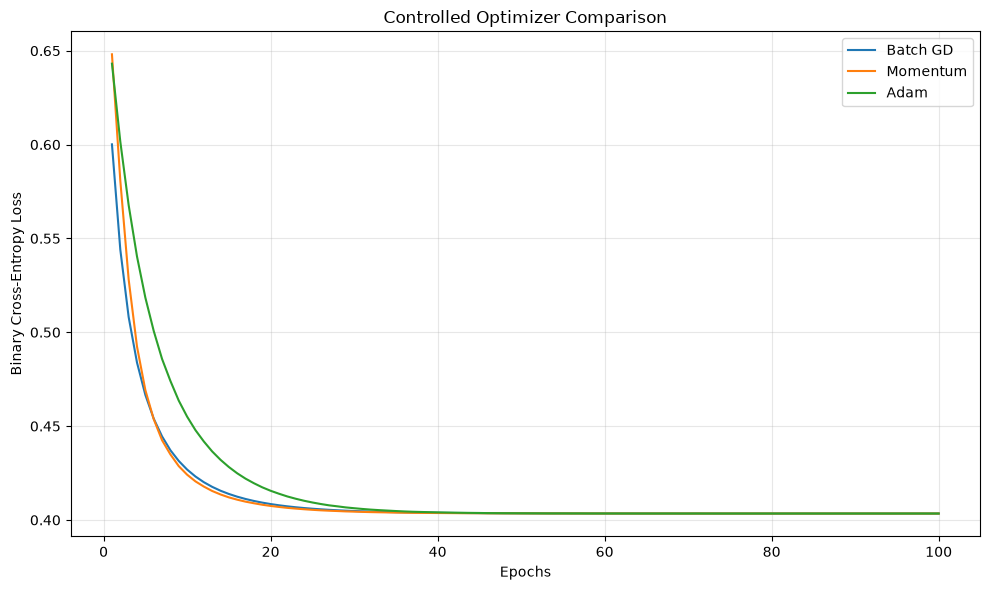

In [5]:
plt.figure(figsize=(10, 6))

for name, model in results.items():

    plt.plot(
        range(1, len(model.loss_history) + 1),
        model.loss_history,
        label=name
    )

plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Controlled Optimizer Comparison")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "results/figures/optimizer_comparison.png",
    dpi=300
)

plt.show()

In [6]:
X_bias = logistic_regression.add_intercept(X)

initial_loss = logistic_regression.binary_cross_entropy(
    X_bias,
    y,
    np.zeros(X_bias.shape[1]),
    l2=0.01
)

summary = []

for name, model in results.items():

    summary.append({
        "Optimizer": name,
        "Initial Loss": initial_loss,
        "Epoch 1 Loss": model.loss_history[0],
        "Final Loss": model.loss_history[-1],
        "Loss Reduction": (
            initial_loss - model.loss_history[-1]
        )
    })

summary_df = pd.DataFrame(summary).set_index("Optimizer")

display(summary_df.round(6))

,Initial Loss,Epoch 1 Loss,Final Loss,Loss Reduction
Optimizer,,,,
Batch GD,0.693147,0.600131,0.403428,0.289719
Momentum,0.693147,0.648104,0.403429,0.289719
Adam,0.693147,0.643113,0.403431,0.289717
